# Finanzas

Trabajamos con los préstamos de Negocios para elegir entre francés y alemán, calcular el valor actual pendiente a mitad y obtener el VA inicial, VAN y TIR de cada préstamo.

Usamos un límite de esfuerzo del 35% y una rentabilidad exigida del 8% efectivo anual. Son supuestos modificables.

## Preparación de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display


### 1. Cargamos los préstamos y filtramos Negocios

Seleccionamos los préstamos de Negocios porque son los que vamos a analizar.


In [2]:
df = pd.read_excel("Data/Prestamos_Data_Alumnos_v5.xlsx")

negocios = df[df["Proposito"] == "Negocios"].copy()

negocios.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estudios,Tipo_Jornada_Laboral,Estado_Civil,Posesion_Hipoteca,Personas_Cargo,Proposito,Fiador,Impago,Prima
7,JKLXIQ,51,56857.0,102886,718,338.0,3,6.18,24.0,0.55,Grado Universitario,Desempleado,Casado,1.0,0.0,Negocios,0.0,0,580.00
19,4UO7DJ,46,45840.0,30473,689,291.0,1,14.28,36.0,0.34,Escolar,Desempleado,Casado,0.0,0.0,Negocios,0.0,0,431.25
36,MO3OJW,36,48156.0,188824,675,161.0,2,13.35,36.0,0.55,Grado Universitario,Jornada completa,Soltero,0.0,1.0,Negocios,0.0,0,760.00
37,I14TTP,42,41472.0,40000,582,312.0,1,11.83,12.0,0.44,Escolar,Jornada completa,Divorciado,1.0,1.0,Negocios,1.0,0,385.66
44,8FUIBH,60,70202.0,40743,652,489.0,2,9.27,48.0,0.25,Grado Universitario,Tiempo parcial,Casado,1.0,0.0,Negocios,1.0,0,535.14


### 2. Nos quedamos con las columnas necesarias

Conservamos ID, importe, tipo, plazo e ingresos porque son las variables que intervienen en los cálculos.


In [3]:
columnas_necesarias = [
    "ID",
    "Monto_Inicial",
    "Ratio_Interes",
    "Duracion",
    "Ingresos"
]

filtrado = negocios[columnas_necesarias].copy()
filtrado = filtrado.drop_duplicates()

columnas_numericas = ["Monto_Inicial", "Ratio_Interes", "Duracion", "Ingresos"]

for columna in columnas_numericas:
    filtrado[columna] = pd.to_numeric(filtrado[columna], errors="coerce")

filtrado = filtrado.replace([np.inf, -np.inf], np.nan)
filtrado = filtrado.dropna(subset=columnas_necesarias)


### 3. Comprobamos que se puedan hacer los cálculos

Comprobamos que el capital y los ingresos sean positivos, la tasa no sea negativa y el plazo sea un número entero de meses. Apartamos los registros con datos insuficientes.


In [4]:
datos_validos = (
    (filtrado["Monto_Inicial"] > 0)
    & (filtrado["Ingresos"] > 0)
    & (filtrado["Ratio_Interes"] >= 0)
    & (filtrado["Duracion"] >= 1)
    & (filtrado["Duracion"] % 1 == 0)
)

df_finanzas = filtrado[datos_validos].copy()
df_finanzas = df_finanzas.reset_index(drop=True)

print("Filas de Negocios:", len(negocios))
print("Filas para analizar:", len(df_finanzas))

Filas de Negocios: 76515
Filas para analizar: 76511


## Objetivo 1. Simular francés y alemán y elegir el sistema

En el francés la cuota es constante. En el alemán se devuelve el mismo capital cada mes y la cuota disminuye. Calculamos ambos para comparar coste y esfuerzo de pago, sin comisiones ni redondeo mensual a céntimos.


### 1. Declaramos el tipo anual

Suponemos que el interés del préstamo es nominal anual (TIN) para convertirlo después en mensual.


In [5]:
TIPO_TASA = 'TIN'

### 2. Convertimos la tasa anual a mensual

Convertimos el tipo anual a mensual porque las cuotas se pagan cada mes. La conversión cambia si el tipo anual es nominal o efectivo.


In [6]:
def tasa_mensual(tasa_anual, tipo='TIN'):
    if not np.isfinite(tasa_anual) or tasa_anual < 0:
        raise ValueError('El tipo de interés debe ser válido y no negativo')
    if tipo == 'TIN':
        interes_mensual = tasa_anual / 12

    elif tipo == 'EFECTIVA':
        interes_mensual = (1 + tasa_anual) ** (1 / 12) - 1

    else:
        raise ValueError('Indica TIN o EFECTIVA')

    return interes_mensual


### 3. Calculamos la cuota francesa

Definimos la cuota constante, incluyendo el caso de interés cero.


In [7]:
def cuota_francesa(monto, interes_mensual, duracion):
    valores = [monto, interes_mensual, duracion]

    if not np.isfinite(valores).all():
        raise ValueError('Revisa los datos del préstamo')
    if monto <= 0 or duracion <= 0 or duracion % 1 != 0:
        raise ValueError('El capital y el plazo deben ser positivos; el plazo debe ser entero')
    if interes_mensual < 0:
        raise ValueError('El interés no puede ser negativo')
    if interes_mensual == 0:
        cuota = monto / duracion

    else:
        factor_descuento = (1 + interes_mensual) ** (-duracion)

        cuota = monto * interes_mensual / (1 - factor_descuento)

    return cuota


### 4. Calculamos el sistema alemán

Partimos del capital pendiente y recorremos los meses. En cada fila guardamos intereses, capital amortizado, cuota y saldo final.


In [8]:
def sistema_aleman(monto, interes, duracion):
    interes_mensual = tasa_mensual(interes, TIPO_TASA)

    if not np.isfinite([monto, duracion]).all():
        raise ValueError("Revisa el capital y el plazo")

    if monto <= 0 or duracion <= 0 or duracion % 1 != 0:
        raise ValueError("El capital debe ser positivo y el plazo entero positivo")

    duracion = int(duracion)

    capital_amortizado = monto / duracion

    capital_pendiente = monto

    tabla = []

    for mes in range(1, duracion + 1):
        capital_inicial = capital_pendiente

        intereses = capital_inicial * interes_mensual

        if mes == duracion:
            capital_amortizado = capital_pendiente

        cuota = capital_amortizado + intereses

        capital_pendiente = capital_inicial - capital_amortizado

        tabla.append(
            [
                mes,
                capital_inicial,
                intereses,
                capital_amortizado,
                cuota,
                capital_pendiente,
            ],
        )
    columnas = [
        'Mes',
        'Capital_inicial',
        'Intereses',
        'Amortizacion',
        'Cuota',
        'Capital_final',
    ]

    return pd.DataFrame(tabla, columns=columnas)


### 5. Calculamos el sistema francés

Calculamos una cuota constante y, cada mes, separamos la parte de intereses y la de capital amortizado.


In [9]:
def sistema_frances(monto, interes, duracion):
    interes_mensual = tasa_mensual(interes, TIPO_TASA)

    cuota = cuota_francesa(monto, interes_mensual, duracion)

    duracion = int(duracion)

    capital_pendiente = monto

    tabla = []

    for mes in range(1, duracion + 1):
        capital_inicial = capital_pendiente

        intereses = capital_inicial * interes_mensual

        capital_amortizado = cuota - intereses

        if mes == duracion:
            capital_amortizado = capital_pendiente

        cuota_mes = capital_amortizado + intereses

        capital_pendiente = capital_inicial - capital_amortizado

        tabla.append(
            [
                mes,
                capital_inicial,
                intereses,
                capital_amortizado,
                cuota_mes,
                capital_pendiente,
            ],
        )
    columnas = [
        'Mes',
        'Capital_inicial',
        'Intereses',
        'Amortizacion',
        'Cuota',
        'Capital_final',
    ]

    return pd.DataFrame(tabla, columns=columnas)


In [10]:
def cuadro_amortizacion(monto, interes, duracion, sistema='Frances'):
    if sistema == 'Frances':
        tabla = sistema_frances(monto, interes, duracion)

    elif sistema == 'Aleman':
        tabla = sistema_aleman(monto, interes, duracion)
    return tabla


### 6. Resumimos cada préstamo

Calculamos las cuotas y los intereses totales de un préstamo. Después repetimos el cálculo en cada fila.


In [11]:
def calcular_resumen(prestamo):
    monto = prestamo['Monto_Inicial']

    interes_anual = prestamo['Ratio_Interes'] / 100

    duracion = prestamo['Duracion']

    interes_mensual = tasa_mensual(interes_anual, TIPO_TASA)

    cuota_frances = cuota_francesa(monto, interes_mensual, duracion)

    amortizacion_aleman = monto / duracion

    cuota_inicial_aleman = amortizacion_aleman + monto * interes_mensual

    cuota_final_aleman = amortizacion_aleman + amortizacion_aleman * interes_mensual

    intereses_frances = cuota_frances * duracion - monto

    intereses_frances = max(0, intereses_frances)

    intereses_aleman = monto * interes_mensual * (duracion + 1) / 2

    ahorro_aleman = intereses_frances - intereses_aleman

    return pd.Series(
        [
            interes_mensual,
            cuota_frances,
            cuota_inicial_aleman,
            cuota_final_aleman,
            intereses_frances,
            intereses_aleman,
            ahorro_aleman,
        ],
    )


In [12]:
def resumen_financiero(datos):
    resultado = datos.copy()

    columnas = [
        'i_mensual',
        'Cuota_Frances',
        'Cuota_inicial_Aleman',
        'Cuota_final_Aleman',
        'Intereses_Frances',
        'Intereses_Aleman',
        'Ahorro_intereses_Aleman',
    ]

    resultado[columnas] = resultado.apply(calcular_resumen, axis=1)

    return resultado


In [13]:
resumen_financiero(df_finanzas.head(1))

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,i_mensual,Cuota_Frances,Cuota_inicial_Aleman,Cuota_final_Aleman,Intereses_Frances,Intereses_Aleman,Ahorro_intereses_Aleman
0,JKLXIQ,102886,6.18,24.0,56857.0,0.00515,4568.319681,4816.779567,4308.994288,6753.672336,6623.28625,130.386086


### 7. Aplicamos las fórmulas a la cartera

Añadimos las columnas financieras a los préstamos válidos.


In [14]:
df_finanzas = resumen_financiero(df_finanzas)

df_finanzas.columns

Index(['ID', 'Monto_Inicial', 'Ratio_Interes', 'Duracion', 'Ingresos',
       'i_mensual', 'Cuota_Frances', 'Cuota_inicial_Aleman',
       'Cuota_final_Aleman', 'Intereses_Frances', 'Intereses_Aleman',
       'Ahorro_intereses_Aleman'],
      dtype='str')

### 8. Elegimos un préstamo de ejemplo

Utilizamos el mismo préstamo para comparar los dos sistemas.


In [15]:
ejemplo = df_finanzas.iloc[0]

### 9. Generamos sus dos cuadros

Construimos el cuadro francés y el alemán.


In [16]:
tabla_frances = sistema_frances(
    ejemplo['Monto_Inicial'],
    ejemplo['Ratio_Interes'] / 100,
    ejemplo['Duracion'],
)

tabla_aleman = sistema_aleman(
    ejemplo['Monto_Inicial'],
    ejemplo['Ratio_Interes'] / 100,
    ejemplo['Duracion'],
)

cuadros_ejemplo = {
    'Frances': tabla_frances,
    'Aleman': tabla_aleman,
}

### 10. Mostramos los cuadros completos

Comparamos cómo se reparte cada cuota entre capital e intereses.


In [17]:
tabla_frances.round(2)

,Mes,Capital_inicial,Intereses,Amortizacion,Cuota,Capital_final
0,1,102886.00,529.86,4038.46,4568.32,98847.54
1,2,98847.54,509.06,4059.25,4568.32,94788.29
2,3,94788.29,488.16,4080.16,4568.32,90708.13
3,4,90708.13,467.15,4101.17,4568.32,86606.96
4,5,86606.96,446.03,4122.29,4568.32,82484.66
5,6,82484.66,424.80,4143.52,4568.32,78341.14
6,7,78341.14,403.46,4164.86,4568.32,74176.28
7,8,74176.28,382.01,4186.31,4568.32,69989.96
8,9,69989.96,360.45,4207.87,4568.32,65782.09
9,10,65782.09,338.78,4229.54,4568.32,61552.55


In [18]:
tabla_aleman.round(2)

,Mes,Capital_inicial,Intereses,Amortizacion,Cuota,Capital_final
0,1,102886.00,529.86,4286.92,4816.78,98599.08
1,2,98599.08,507.79,4286.92,4794.70,94312.17
2,3,94312.17,485.71,4286.92,4772.62,90025.25
3,4,90025.25,463.63,4286.92,4750.55,85738.33
4,5,85738.33,441.55,4286.92,4728.47,81451.42
5,6,81451.42,419.47,4286.92,4706.39,77164.50
6,7,77164.50,397.40,4286.92,4684.31,72877.58
7,8,72877.58,375.32,4286.92,4662.24,68590.67
8,9,68590.67,353.24,4286.92,4640.16,64303.75
9,10,64303.75,331.16,4286.92,4618.08,60016.83


### 11. Comparamos las cuotas en un gráfico

Observamos la cuota francesa constante y la alemana decreciente.


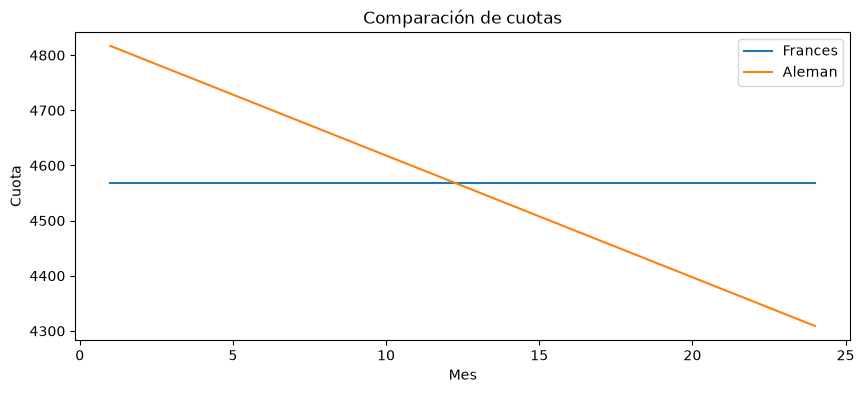

In [19]:
plt.figure(figsize=(10, 4))
plt.plot(tabla_frances['Mes'], tabla_frances['Cuota'], label='Frances')
plt.plot(tabla_aleman['Mes'], tabla_aleman['Cuota'], label='Aleman')
plt.xlabel('Mes')
plt.ylabel('Cuota')
plt.title('Comparación de cuotas')
plt.legend()
plt.show()


### 12. Elegimos entre alemán y francés

Elegimos alemán si su cuota inicial no supera el 35% de los ingresos mensuales y sus intereses son menores. En los demás casos elegimos francés.

Todos los préstamos válidos reciben un sistema. `Supera_limite` indica si la cuota elegida supera el límite: asignar un sistema no significa que el cliente pueda pagarlo. Solo consideramos la cuota nueva, porque no conocemos las cuotas reales de otras deudas.


In [20]:
LIMITE_ESFUERZO = 0.35


In [21]:
def recomendar_sistema(prestamo, limite=0.35):

    ingresos_mensuales = prestamo["Ingresos"] / 12

    if not np.isfinite(ingresos_mensuales) or ingresos_mensuales <= 0:
        raise ValueError("Necesitamos ingresos positivos para comparar las cuotas")

    cuota_aleman = prestamo["Cuota_inicial_Aleman"]
    cuota_frances = prestamo["Cuota_Frances"]

    esfuerzo_aleman = cuota_aleman / ingresos_mensuales
    esfuerzo_frances = cuota_frances / ingresos_mensuales

    intereses_aleman = prestamo["Intereses_Aleman"]
    intereses_frances = prestamo["Intereses_Frances"]

    aleman_mas_barato = intereses_aleman < intereses_frances - 0.00000001

    if esfuerzo_aleman <= limite and aleman_mas_barato:

        sistema = "Aleman"
        motivo = "La cuota inicial entra en el límite y se pagan menos intereses"
        cuota_elegida = cuota_aleman
        intereses_elegidos = intereses_aleman
        esfuerzo_elegido = esfuerzo_aleman

    else:

        sistema = "Frances"
        cuota_elegida = cuota_frances
        intereses_elegidos = intereses_frances
        esfuerzo_elegido = esfuerzo_frances

        if not aleman_mas_barato:
            motivo = "No hay ahorro de intereses con el alemán; elegimos cuota constante"
        elif esfuerzo_frances <= limite:
            motivo = "La cuota francesa entra en el límite y la inicial alemana no"
        else:
            motivo = "Ambas superan el límite; asignamos francés por su menor cuota inicial"

    supera_limite = esfuerzo_elegido > limite

    return pd.Series([
        sistema,
        motivo,
        esfuerzo_frances,
        esfuerzo_aleman,
        cuota_elegida,
        intereses_elegidos,
        esfuerzo_elegido,
        supera_limite
    ])


### 13. Aplicamos la elección a todos los préstamos

Aplicamos la regla a cada préstamo utilizando las cuotas y los intereses calculados antes.


In [22]:
decisiones = df_finanzas.copy()

columnas_decision = [
    "Sistema_recomendado",
    "Motivo",
    "Esfuerzo_Frances",
    "Esfuerzo_Aleman",
    "Cuota_maxima_elegida",
    "Intereses_elegidos",
    "Esfuerzo_elegido",
    "Supera_limite"
]

decisiones[columnas_decision] = decisiones.apply(
    recomendar_sistema,
    axis=1,
    limite=LIMITE_ESFUERZO
)


In [23]:
decisiones[["ID", "Sistema_recomendado", "Motivo", "Supera_limite"]].head(10)


,ID,Sistema_recomendado,Motivo,Supera_limite
0,JKLXIQ,Frances,Ambas superan el límite; asignamos francés por...,True
1,4UO7DJ,Aleman,La cuota inicial entra en el límite y se pagan...,False
2,MO3OJW,Frances,Ambas superan el límite; asignamos francés por...,True
3,I14TTP,Frances,Ambas superan el límite; asignamos francés por...,True
4,8FUIBH,Aleman,La cuota inicial entra en el límite y se pagan...,False
5,7DK4AB,Frances,Ambas superan el límite; asignamos francés por...,True
6,UTAX3Y,Aleman,La cuota inicial entra en el límite y se pagan...,False
7,R88ZD9,Aleman,La cuota inicial entra en el límite y se pagan...,False
8,54QB5O,Frances,Ambas superan el límite; asignamos francés por...,True
9,VSK4GD,Frances,Ambas superan el límite; asignamos francés por...,True


In [24]:
decisiones["Sistema_recomendado"].value_counts()


Sistema_recomendado
Frances    39099
Aleman     37412
Name: count, dtype: int64

### 14. Comprobamos las cuotas elegidas

Esta tabla indica cuántas cuotas superan el límite dentro de cada sistema. La columna no cambia la asignación.


In [25]:
pd.crosstab(decisiones["Sistema_recomendado"], decisiones["Supera_limite"])


Supera_limite,False,True
Sistema_recomendado,,
Aleman,37412,0
Frances,3432,35667


### 15. Obtenemos las cuotas del sistema seleccionado

Creamos una lista de cuotas con un bucle. Así no guardamos los cuadros completos de todos los préstamos a la vez.


In [26]:
def cuotas_seleccionadas(prestamo):

    monto = prestamo["Monto_Inicial"]
    duracion = int(prestamo["Duracion"])
    interes_mensual = prestamo["i_mensual"]
    sistema = prestamo["Sistema_recomendado"]

    capital_pendiente = monto
    amortizacion_aleman = monto / duracion
    cuotas = []

    for mes in range(1, duracion + 1):

        intereses = capital_pendiente * interes_mensual

        if sistema == "Aleman":
            amortizacion = amortizacion_aleman
        elif sistema == "Frances":
            amortizacion = prestamo["Cuota_Frances"] - intereses
        else:
            raise ValueError("El sistema debe ser Frances o Aleman")

        if mes == duracion:
            amortizacion = capital_pendiente

        cuota = amortizacion + intereses
        cuotas.append(cuota)

        capital_pendiente = capital_pendiente - amortizacion

    return cuotas


## Objetivo 2. Valor presente de las cuotas pendientes a mitad

Descontamos las cuotas pendientes justo después de pagar la cuota de mitad del plazo. Si el plazo es impar, usamos la mitad inferior.

Utilizamos el interés mensual del préstamo. Así obtenemos el VA en la fecha de mitad, que coincide con el capital pendiente en ese momento.


In [27]:
def valor_actual_mitad(prestamo):

    cuotas = cuotas_seleccionadas(prestamo)
    interes_mensual = prestamo["i_mensual"]
    duracion = int(prestamo["Duracion"])

    meses_pagados = duracion // 2
    cuotas_pendientes = cuotas[meses_pagados:]

    valor_actual = 0
    mes = 1

    for cuota in cuotas_pendientes:

        valor_cuota = cuota / (1 + interes_mensual) ** mes
        valor_actual = valor_actual + valor_cuota
        mes = mes + 1

    return valor_actual


In [28]:
decisiones["Mes_mitad"] = decisiones["Duracion"] // 2

decisiones["VA_mitad_elegido"] = decisiones.apply(valor_actual_mitad, axis=1)


In [29]:
decisiones[["ID", "Sistema_recomendado", "Mes_mitad", "VA_mitad_elegido"]].head(10)


,ID,Sistema_recomendado,Mes_mitad,VA_mitad_elegido
0,JKLXIQ,Frances,12.0,53028.007665
1,4UO7DJ,Aleman,18.0,15236.500000
2,MO3OJW,Frances,18.0,103781.860208
3,I14TTP,Frances,6.0,20588.433542
4,8FUIBH,Aleman,24.0,20371.500000
5,7DK4AB,Frances,30.0,22676.721878
6,UTAX3Y,Aleman,30.0,14449.000000
7,R88ZD9,Aleman,30.0,20000.000000
8,54QB5O,Frances,18.0,63821.805363
9,VSK4GD,Frances,18.0,33689.832551


## Apartado final. VA, VAN y TIR de cada préstamo

Calculamos estas medidas para valorar cada préstamo:

- **VA:** suma de las cuotas futuras descontadas.
- **VAN:** VA menos el importe entregado al principio.
- **TIR:** tasa que hace que el VAN sea cero.

Tomamos la perspectiva del prestamista: entrega el capital y cobra las cuotas. Suponemos pagos completos y puntuales, sin gastos, impuestos ni comisiones.

Para el VAN usamos un 8% efectivo anual exigido, como supuesto modificable, y lo convertimos a mensual. La TIR mensual se convierte a anual efectiva con `(1 + TIR_mensual)**12 - 1`.


### 1. Indicamos la rentabilidad exigida

Fijamos una tasa exigida común para valorar los préstamos con el mismo criterio. Se puede modificar para estudiar otro escenario.


In [30]:
TASA_EXIGIDA_ANUAL = 0.08

TASA_EXIGIDA_MENSUAL = (1 + TASA_EXIGIDA_ANUAL) ** (1 / 12) - 1


### 2. Creamos la función del VAN

Sumamos los flujos descontados. El primero es el desembolso inicial, con signo negativo, y corresponde al momento cero.


In [31]:
def calcular_van(flujos, tasa):

    valor_actual_neto = 0
    periodo = 0

    for flujo in flujos:

        valor_flujo = flujo / (1 + tasa) ** periodo
        valor_actual_neto = valor_actual_neto + valor_flujo
        periodo = periodo + 1

    return valor_actual_neto


### 3. Creamos la función de la TIR

Buscamos la tasa que deja el VAN cerca de cero. Si el VAN es positivo subimos la tasa; si es negativo la bajamos.

La función admite un desembolso inicial negativo y cobros posteriores no negativos. Los flujos con varios cambios de signo pueden tener más de una TIR y necesitan otro análisis.


In [32]:
def calcular_tir(flujos):

    if flujos[0] >= 0 or min(flujos[1:]) < 0 or max(flujos[1:]) <= 0:
        raise ValueError("Se necesita un desembolso negativo y cobros posteriores no negativos")

    tasa_baja = -0.99
    tasa_alta = 1.0

    if calcular_van(flujos, tasa_baja) < 0:
        raise ValueError("La TIR queda por debajo del intervalo de cálculo")

    while calcular_van(flujos, tasa_alta) > 0:
        tasa_alta = tasa_alta * 2

    for intento in range(50):

        tasa_prueba = (tasa_baja + tasa_alta) / 2
        van_prueba = calcular_van(flujos, tasa_prueba)

        if van_prueba > 0:
            tasa_baja = tasa_prueba
        else:
            tasa_alta = tasa_prueba

    tir = (tasa_baja + tasa_alta) / 2

    return tir


### 4. Calculamos los resultados del sistema elegido

Calculamos VA, VAN y TIR con las cuotas del sistema elegido. Este VA valora todas las cuotas al inicio con la tasa exigida; el VA anterior valoraba solo lo pendiente a mitad con el interés del préstamo.


In [33]:
def calcular_va_van_tir(prestamo):

    monto = prestamo["Monto_Inicial"]
    cuotas = cuotas_seleccionadas(prestamo)

    flujos = [-monto] + cuotas

    van = calcular_van(flujos, TASA_EXIGIDA_MENSUAL)
    va_cuotas = van + monto

    tir_mensual = calcular_tir(flujos)
    tir_anual = (1 + tir_mensual) ** 12 - 1

    return pd.Series([
        va_cuotas,
        van,
        tir_mensual,
        tir_anual
    ])


In [34]:
columnas_financieras = [
    "VA_cuotas_origen_k",
    "VAN_prestamista_k",
    "TIR_mensual",
    "TIR_anual_efectiva"
]

decisiones[columnas_financieras] = decisiones.apply(calcular_va_van_tir, axis=1)


### 5. Interpretamos el VAN y la TIR

Un VAN positivo y una TIR superior a la tasa exigida indican que el préstamo supera esa rentabilidad bajo los supuestos usados. Un VAN cero significa que la cubre exactamente.

Con el mismo tipo y sin gastos, francés y alemán tienen la misma TIR, aunque cambien sus cuotas e intereses totales. Descontar al propio tipo del préstamo daría un VAN aproximadamente cero.

Esta interpretación es contractual: no incluye pérdidas por impago ni gastos y no equivale a aprobar la operación.


In [35]:
def interpretar_resultado(prestamo):

    van = prestamo["VAN_prestamista_k"]
    tir_anual = prestamo["TIR_anual_efectiva"]

    if abs(van) < 0.01:
        resultado = "Cubre aproximadamente la rentabilidad exigida"
    elif van > 0 and tir_anual > TASA_EXIGIDA_ANUAL:
        resultado = "Supera la rentabilidad exigida bajo los supuestos contractuales"
    else:
        resultado = "No alcanza la rentabilidad exigida en este escenario"

    return resultado


In [36]:
decisiones["Interpretacion_VAN_TIR"] = decisiones.apply(interpretar_resultado, axis=1)

decisiones["TIR_anual_porcentaje"] = decisiones["TIR_anual_efectiva"] * 100

columnas_resultado = [
    "ID",
    "Sistema_recomendado",
    "Supera_limite",
    "VA_mitad_elegido",
    "VA_cuotas_origen_k",
    "VAN_prestamista_k",
    "TIR_anual_porcentaje",
    "Interpretacion_VAN_TIR"
]

decisiones[columnas_resultado].head(10)


,ID,Sistema_recomendado,Supera_limite,VA_mitad_elegido,VA_cuotas_origen_k,VAN_prestamista_k,TIR_anual_porcentaje,Interpretacion_VAN_TIR
0,JKLXIQ,Frances,True,53028.007665,101292.947614,-1593.052386,6.358089,No alcanza la rentabilidad exigida en este esc...
1,4UO7DJ,Aleman,False,15236.500000,33318.289981,2845.289981,15.252711,Supera la rentabilidad exigida bajo los supues...
2,MO3OJW,Frances,True,103781.860208,204888.449210,16064.449210,14.197917,Supera la rentabilidad exigida bajo los supues...
3,I14TTP,Frances,True,20588.433542,40879.524446,879.524446,12.492986,Supera la rentabilidad exigida bajo los supues...
4,8FUIBH,Aleman,False,20371.500000,41904.082247,1161.082247,9.674179,Supera la rentabilidad exigida bajo los supues...
5,7DK4AB,Frances,True,22676.721878,42997.973451,2997.973451,11.373041,Supera la rentabilidad exigida bajo los supues...
6,UTAX3Y,Aleman,False,14449.000000,30964.535376,2066.535376,11.483469,Supera la rentabilidad exigida bajo los supues...
7,R88ZD9,Aleman,False,20000.000000,39722.073436,-277.926564,7.666915,No alcanza la rentabilidad exigida en este esc...
8,54QB5O,Frances,True,63821.805363,124579.188612,7290.188612,12.526409,Supera la rentabilidad exigida bajo los supues...
9,VSK4GD,Frances,True,33689.832551,62172.168284,-2974.831716,4.677376,No alcanza la rentabilidad exigida en este esc...


In [37]:
decisiones["Interpretacion_VAN_TIR"].value_counts()


Interpretacion_VAN_TIR
Supera la rentabilidad exigida bajo los supuestos contractuales    58936
No alcanza la rentabilidad exigida en este escenario               17575
Name: count, dtype: int64

## Interpretación final

La elección del sistema compara la cuota y los intereses que paga el prestatario. El VAN y la TIR valoran el préstamo desde la perspectiva del prestamista.

Estos resultados no demuestran la rentabilidad del negocio financiado. Para estudiarla necesitaríamos sus cobros y pagos netos, de los cuales no disponemos.
